In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/abc-2.csv", header=None)
P = df.to_numpy(dtype=float)
N = len(P)

df["Ngay"] = np.arange(1, N + 1)
df["Thang"] = np.minimum((df["Ngay"] - 1) // 30 + 1, 12)
df["Quy"] = (df["Thang"] - 1) // 3 + 1

df["Close"] = P[:, 6]
df["TC"] = df["Close"].shift(1)
df.loc[0, "TC"] = df.loc[0, "Close"]
df["San"] = df["TC"] * 0.9
df["Tran"] = df["TC"] * 1.1

df["Mean"] = P.mean(axis=1)
df["High"] = P.max(axis=1)
df["Low"] = P.min(axis=1)

print(df[["Ngay", "Thang", "Quy", "Close", "Mean"]].head())


   Ngay  Thang  Quy         Close          Mean
0     1      1    1  11000.000000  10339.891099
1     2      1    1   9900.000000  11159.342919
2     3      1    1   9200.395883   9814.388805
3     4      1    1   9952.274656   9304.085482
4     5      1    1  10433.685039  10309.824607


           mean      std       min       max   Bien_do
Thang                                                 
1       8441.49  1671.14   5852.01  11315.22   5463.21
2       8711.75  1724.04   5986.38  12910.58   6924.20
3       9666.20  1244.47   7649.94  12180.88   4530.94
4       7705.56  1486.81   5219.19  11158.72   5939.53
5       6644.80   778.53   4913.71   7941.37   3027.66
6       9356.20  2116.10   6538.27  13822.05   7283.78
7      11615.71  1035.75   9425.39  14613.18   5187.80
8      12954.00  1692.21  10102.75  16572.38   6469.63
9      15400.31  1109.05  13318.88  18281.72   4962.84
10     14883.67  1696.79  11966.40  17871.70   5905.31
11     15768.71  3960.50  10341.13  23066.75  12725.62
12      7435.73  1823.47   4776.20  10560.51   5784.31


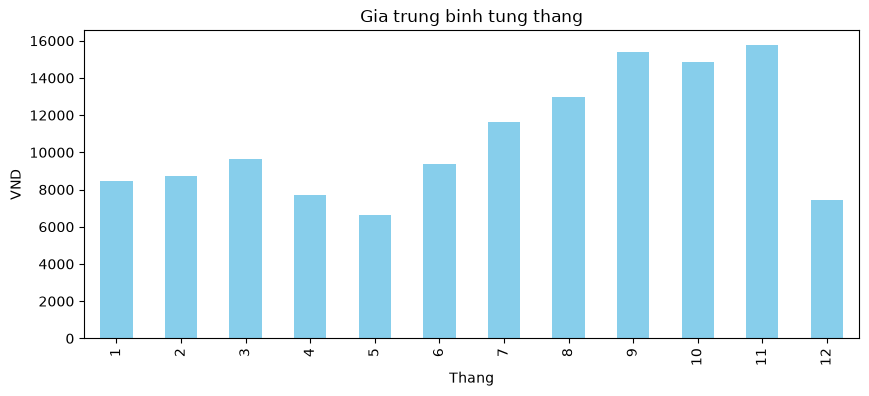

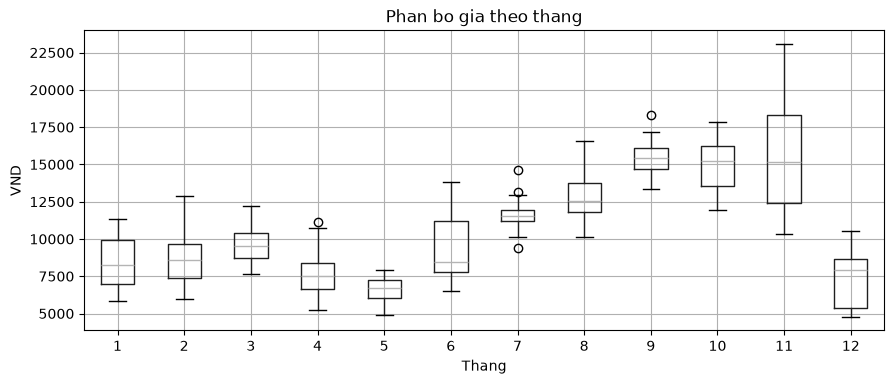

Thang co bien do lon nhat: 11
Thang co do lech chuan lon nhat: 11
Nhan xet: Hop cang cao thi gia cang phan tan.


In [2]:

# Gia trung binh va do lech chuan moi thang
thang = df.groupby("Thang")["Mean"].agg(["mean", "std", "min", "max"])
thang["Bien_do"] = thang["max"] - thang["min"]
print(thang.round(2))

# Bieu do cot
thang["mean"].plot(kind="bar", color="skyblue", figsize=(10, 4))
plt.title("Gia trung binh tung thang")
plt.xlabel("Thang")
plt.ylabel("VND")
plt.show()

# Boxplot
df.boxplot(column="Mean", by="Thang", figsize=(10, 4))
plt.title("Phan bo gia theo thang")
plt.suptitle("")
plt.xlabel("Thang")
plt.ylabel("VND")
plt.show()

print("Thang co bien do lon nhat:", thang["Bien_do"].idxmax())
print("Thang co do lech chuan lon nhat:", thang["std"].idxmax())
print("Nhan xet: Hop cang cao thi gia cang phan tan.")


         mean      std      min       max   Bien_do
Quy                                                
1     8939.81  1631.63  5852.01  12910.58   7058.58
2     7902.19  1906.70  4913.71  13822.05   8908.34
3    13323.34  2041.18  9425.39  18281.72   8856.33
4    12419.18  4657.91  4776.20  23066.75  18290.55


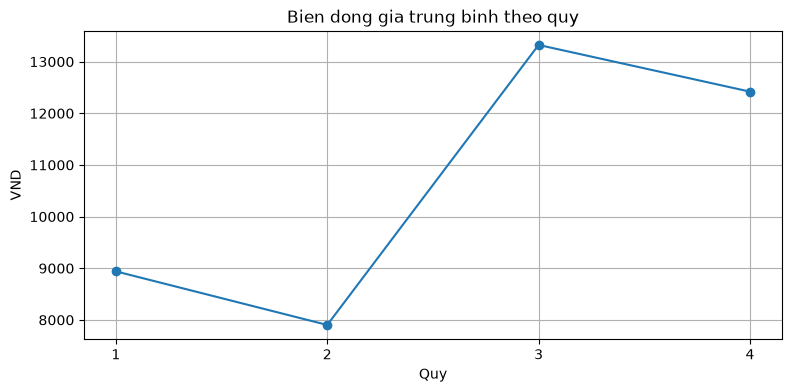

Quy 1: thay doi -8.28%
Quy 2: thay doi 7.26%
Quy 3: thay doi 46.92%
Quy 4: thay doi -62.91%


In [3]:

quy = df.groupby("Quy")["Mean"].agg(["mean", "std", "min", "max"])
quy["Bien_do"] = quy["max"] - quy["min"]

print(quy.round(2))

quy["mean"].plot(marker="o", figsize=(9, 4))
plt.title("Bien dong gia trung binh theo quy")
plt.xlabel("Quy")
plt.ylabel("VND")
plt.xticks([1, 2, 3, 4])
plt.grid()
plt.show()

for q in range(1, 5):
    a = df[df["Quy"] == q]["Close"]
    print(f"Quy {q}: thay doi {(a.iloc[-1]/a.iloc[0]-1)*100:.2f}%")


In [4]:

# Gia dong cua bang san, tran, tham chieu
san = np.isclose(df["Close"], df["San"], atol=0.5)
tran = np.isclose(df["Close"], df["Tran"], atol=0.5)
tc = np.isclose(df["Close"], df["TC"], atol=0.5)

# Co gia giao dich vuot ngoai bien do cho phep
ngoai = ((P < df["San"].to_numpy()[:, None] - 0.5) |
         (P > df["Tran"].to_numpy()[:, None] + 0.5)).any(axis=1)

bat_thuong = df[san | tran | tc | ngoai].copy()

bat_thuong["Ly_do"] = [
    ", ".join(
        ten for dieu_kien, ten in [
            (san[i], "Gia san"),
            (tran[i], "Gia tran"),
            (tc[i], "Tham chieu"),
            (ngoai[i], "Ngoai bien do")
        ] if dieu_kien
    )
    for i in bat_thuong.index
]

print(bat_thuong[
    ["Ngay", "Close", "TC", "San", "Tran", "Ly_do"]
].to_string(index=False))


 Ngay        Close           TC          San         Tran                     Ly_do
    1 11000.000000 11000.000000  9900.000000 12100.000000 Tham chieu, Ngoai bien do
    2  9900.000000 11000.000000  9900.000000 12100.000000                   Gia san
    6 11477.053543 10433.685039  9390.316535 11477.053543                  Gia tran
    7 10329.348189 11477.053543 10329.348189 12624.758897                   Gia san
    8 11362.283007 10329.348189  9296.413370 11362.283008                  Gia tran
    9 10226.054707 11362.283007 10226.054706 12498.511308                   Gia san
   13  7898.496796  8776.107551  7898.496796  9653.718306                   Gia san
   14  7108.647117  7898.496796  7108.647116  8688.346476                   Gia san
   16  7968.440703  7244.037003  6519.633303  7968.440703                  Gia tran
   18  7802.809058  8669.787842  7802.809058  9536.766626                   Gia san
   19  7022.528152  7802.809058  7022.528152  8583.089964                   

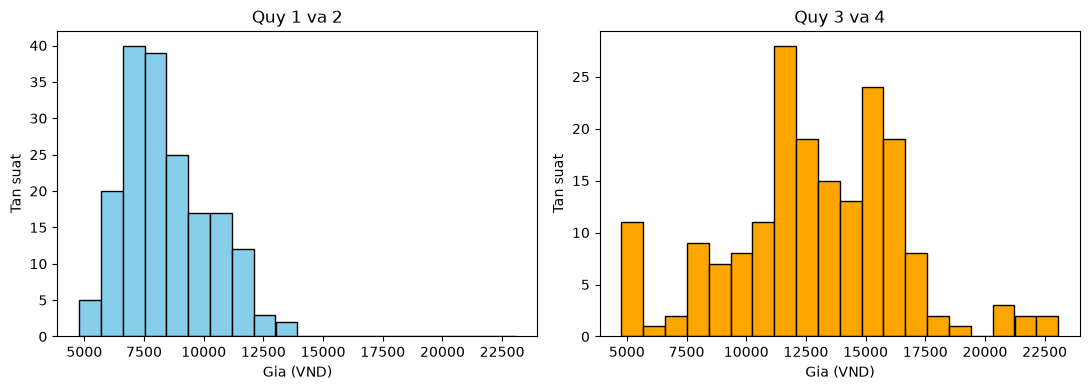

Trung binh 2 quy dau: 8421.0
Trung binh 2 quy cuoi: 12859.04


In [5]:

dau = df[df["Quy"] <= 2]["Mean"]
cuoi = df[df["Quy"] >= 3]["Mean"]

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
bins = np.linspace(df["Mean"].min(), df["Mean"].max(), 21)

ax[0].hist(dau, bins=bins, color="skyblue", edgecolor="black")
ax[0].set_title("Quy 1 va 2")

ax[1].hist(cuoi, bins=bins, color="orange", edgecolor="black")
ax[1].set_title("Quy 3 va 4")

for a in ax:
    a.set_xlabel("Gia (VND)")
    a.set_ylabel("Tan suat")

plt.tight_layout()
plt.show()

print("Trung binh 2 quy dau:", round(dau.mean(), 2))
print("Trung binh 2 quy cuoi:", round(cuoi.mean(), 2))


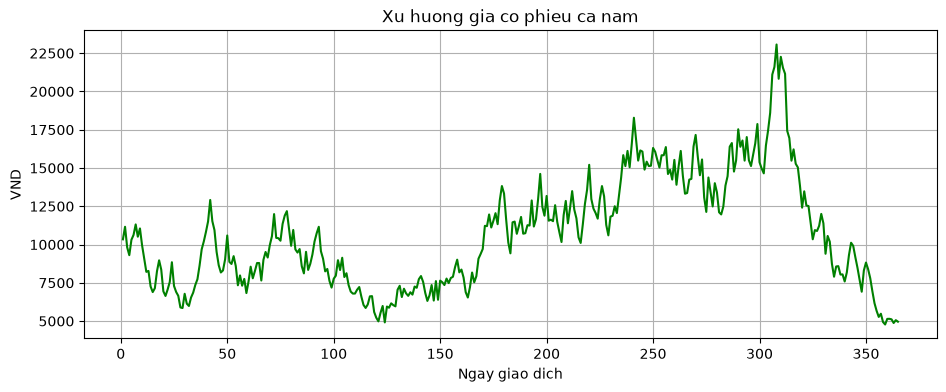

Thay doi gia ca nam: -52.23%
Xu huong: Giam
Bien do toan nam: 21248.236758
Ngay co bien do trong ngay lon nhat: 308
Bien do ngay do: 4647.279060000001
Ngay gia cao nhat: 308
Ngay gia thap nhat: 363


In [6]:

plt.figure(figsize=(11, 4))
plt.plot(df["Ngay"], df["Mean"], color="green")
plt.title("Xu huong gia co phieu ca nam")
plt.xlabel("Ngay giao dich")
plt.ylabel("VND")
plt.grid()
plt.show()

ty_le = (df["Close"].iloc[-1] / df["Close"].iloc[0] - 1) * 100

print(f"Thay doi gia ca nam: {ty_le:.2f}%")
print("Xu huong:", "Tang" if ty_le > 0 else "Giam" if ty_le < 0 else "Di ngang")

# Bien do toan nam
print("Bien do toan nam:", df["High"].max() - df["Low"].min())

# Ngay dao dong manh nhat
df["Bien_do"] = df["High"] - df["Low"]
i = df["Bien_do"].idxmax()

print("Ngay co bien do trong ngay lon nhat:", df.loc[i, "Ngay"])
print("Bien do ngay do:", df.loc[i, "Bien_do"])

print("Ngay gia cao nhat:", df.loc[df["High"].idxmax(), "Ngay"])
print("Ngay gia thap nhat:", df.loc[df["Low"].idxmin(), "Ngay"])


In [7]:

# Mau xanh khi gia dong cua lon hon tham chieu
# Duong di xuong khi gia trung binh giam

df["Mean_truoc"] = df["Mean"].shift(1)

ket_qua = df[
    (df["Close"] > df["TC"]) &
    (df["Mean"] < df["Mean_truoc"])
]

print(ket_qua[
    ["Ngay", "Close", "TC", "Mean_truoc", "Mean"]
].to_string(index=False))

print("\nGiai thich:")
print("Mau xanh: Gia dong cua > gia tham chieu.")
print("Duong di xuong: Gia trung binh < ngay truoc.")
print("Hai dai luong khac nhau nen khong mau thuan.")


 Ngay        Close           TC   Mean_truoc         Mean
    4  9952.274656  9200.395883  9814.388805  9304.085482
    8 11362.283007 10329.348189 11315.219879 10510.118995
   12  8776.107551  8454.001422  9069.396602  8213.331431
   15  7244.037003  7108.647117  7262.591400  6893.857700
   21  6924.969943  6795.564295  6942.156886  6641.095928
   29  6544.644028  5949.676389  5889.966052  5852.005237
   31  5937.942788  5890.179625  6783.495277  6136.210017
   32  6531.737067  5937.942788  6136.210017  5986.380739
   47  8592.158174  7811.052885  8643.756053  8174.363049
   52  9395.967894  8541.788994  8866.814361  8730.560660
   55  8371.807393  7610.733994  8596.720942  7338.898895
   57  7950.257801  7534.626654  7982.579704  7310.003302
   59  7870.755223  7155.232021  7755.544851  6830.642759
   62  8244.900393  7495.363994  8552.570460  7794.781193
   66  8988.338503  8171.216821  8791.737054  7649.939541
   69  9788.300629  8898.455118  9514.461638  9150.149414
   74 10167.54